# 02 · Modelling the Likelihood of Procurement Failure

**PhilGEPS procurement-failure risk · Notebook 2 of 3 · Roadmap step 6**
**Input:** `data/processed/bids_public_bidding.parquet` from notebook 01 (one row per Public Bidding bid, PhilGEPS 1.5 + 2.0, 2023 Q1 – 2026 Q2, `Closed` bids removed).
**Target:** `Target_Failed` = 1 if the bid ended in a failed bidding **or was cancelled**, 0 if it was awarded. Other statuses are excluded (notebook 01, §5.2).

## Approach

1. **Split.** The merged 1.5 + 2.0 bid table is split at random into **train (70%)**, **validation (15%)** and **test (15%)**, stratified by outcome and source system. Each bid is in exactly one set, so line items of one bid never cross sets. This differs from LT8, which split by year. The year-based view is kept as a robustness check in notebook 03, because a random split mixes periods and can overstate how well the model works on future notices.
2. **Baselines.** A majority-class model, and a random ranking.
3. **Original 5 features** (as in LT8 §6.1): log approved budget, funding source, procurement category, region, publication month. Four models are compared on the validation set: logistic regression, decision tree, random forest and histogram gradient boosting.
4. **Expanded features**, all available at publication: the original 5 plus bidding-window length, number of line items, contract duration, classification, organisation type, government branch, funding instrument, applicable procurement rules, lot type, publication weekday, source system, and a multi-funding-source flag.
5. **Final model.** The best combination on validation PR-AUC is chosen and evaluated **once** on the test set. Its scores are calibrated on the validation set, so they can be read as probabilities of failure.
6. **Sensitivity.** The final configuration is refitted with only `Failed` counted as failure (Cancelled bids left out).

**Metrics.** Failed or cancelled bids are about 20% of labelled bids, so accuracy is not informative: predicting "awarded" for every bid is 80% accurate. The metrics used are:

- **ROC-AUC:** ranking quality overall.
- **PR-AUC (average precision):** ranking quality focused on the failed class.
- **Review-queue metrics:** precision, recall and lift when staff review only the top *k*% of notices by predicted risk (LT8 §6.2).

In [1]:
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (PrecisionRecallDisplay, RocCurveDisplay, brier_score_loss)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

import procurement_failure as pf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pf.MODELS.mkdir(parents=True, exist_ok=True)

bids = pd.read_parquet(pf.BIDS)
labelled = bids[bids["Target_Failed"].notna()].reset_index(drop=True)
print(f"Bids: {len(bids):,} | labelled: {len(labelled):,} | failure rate: {labelled.Target_Failed.mean() * 100:.2f}%")

Bids: 629,920 | labelled: 615,397 | failure rate: 20.01%


## 6.1 Train / validation / test split on the merged dataset

The split is stratified on outcome × source system, so each set keeps the same failure rate and the same share of PhilGEPS 2.0 bids. The assignment is saved so that notebook 03 uses exactly the same test set.

In [2]:
def split_three(frame, target, seed=pf.RANDOM_STATE):
    strata = frame[target].astype(int).astype(str) + "_" + frame["Source System"].astype(str)
    train_idx, rest_idx = train_test_split(frame.index, test_size=0.30, stratify=strata, random_state=seed)
    val_idx, test_idx = train_test_split(rest_idx, test_size=0.50, stratify=strata.loc[rest_idx], random_state=seed)
    split = pd.Series("train", index=frame.index)
    split.loc[val_idx] = "validation"
    split.loc[test_idx] = "test"
    return split

labelled["split"] = split_three(labelled, "Target_Failed")
labelled[pf.KEY + ["split"]].to_parquet(pf.SPLITS, index=False)

split_summary = labelled.groupby(["split", "Source System"], observed=True)["Target_Failed"].agg(
    Bids="size", Failed="sum", **{"Failure rate": "mean"})
display(split_summary)

train = labelled[labelled.split == "train"]
val = labelled[labelled.split == "validation"]
test = labelled[labelled.split == "test"]
y_train, y_val, y_test = train.Target_Failed.astype(int), val.Target_Failed.astype(int), test.Target_Failed.astype(int)
print(f"train {len(train):,} | validation {len(val):,} | test {len(test):,}")

Bids      Failed  Failure rate
split      Source System                                  
test       1.5             91038 17,979.0000        0.1975
           2.0              1272    488.0000        0.3836
train      1.5            424842 83,902.0000        0.1975
           2.0              5935  2,278.0000        0.3838
validation 1.5             91039 17,980.0000        0.1975
           2.0              1271    488.0000        0.3839

train 430,777 | validation 92,310 | test 92,310


## 6.2 Baselines

- **Majority class:** always predicts *awarded*. It shows why accuracy is misleading: high accuracy, zero failures detected.
- **Random ranking:** the expected PR-AUC equals the failure rate, and lift is 1 at every review share.

In [3]:
majority = DummyClassifier(strategy="most_frequent").fit(train[["log_approved_budget"]], y_train)
pred = majority.predict(val[["log_approved_budget"]])
print(f"Majority-class validation accuracy: {(pred == y_val).mean() * 100:.1f}% | failures detected: {int((pred[y_val == 1] == 1).sum())} of {int(y_val.sum()):,}")
print(f"Random-ranking validation PR-AUC (= failure rate): {y_val.mean():.4f} | ROC-AUC: 0.5 | lift: 1.0")

Majority-class validation accuracy: 80.0% | failures detected: 0 of 18,468
Random-ranking validation PR-AUC (= failure rate): 0.2001 | ROC-AUC: 0.5 | lift: 1.0


## 6.3 Candidate models

Every model uses the same preprocessing:

- **Logistic regression, decision tree, random forest:** numeric features are median-imputed and standardised. Categorical features are one-hot encoded, with categories seen fewer than 50 times grouped as *infrequent*.
- **Gradient boosting:** uses native categorical splits.

All four use class weighting, so the rare failed class is not ignored. Settings are fixed and moderate rather than tuned. As LT8 concluded, the priority is a sound evaluation, not the last point of AUC.

In [4]:
def make_models(numeric, categorical):
    onehot = lambda: pf.one_hot_preprocessor(numeric, categorical)
    return {
        "Logistic regression": Pipeline([("prep", onehot()), ("model", LogisticRegression(
            class_weight="balanced", max_iter=3000))]),
        "Decision tree": Pipeline([("prep", onehot()), ("model", DecisionTreeClassifier(
            max_depth=12, min_samples_leaf=100, class_weight="balanced", random_state=pf.RANDOM_STATE))]),
        "Random forest": Pipeline([("prep", onehot()), ("model", RandomForestClassifier(
            n_estimators=200, min_samples_leaf=20, max_features="sqrt", max_samples=0.5,
            class_weight="balanced_subsample", n_jobs=-1, random_state=pf.RANDOM_STATE))]),
        "Gradient boosting": Pipeline([("prep", pf.ordinal_preprocessor(numeric, categorical)), ("model", HistGradientBoostingClassifier(
            categorical_features=[False] * len(numeric) + [True] * len(categorical),
            learning_rate=0.1, max_iter=500, early_stopping=True, validation_fraction=0.1,
            class_weight="balanced", random_state=pf.RANDOM_STATE))]),
    }


def fit_and_validate(feature_set):
    numeric, categorical = pf.FEATURE_SETS[feature_set]
    X_tr = pf.model_frame(train, numeric, categorical)
    X_va = pf.model_frame(val, numeric, categorical)
    rows, fitted = [], {}
    for name, model in make_models(numeric, categorical).items():
        t = time.time()
        model.fit(X_tr, y_train)
        score = model.predict_proba(X_va)[:, 1]
        rows.append({"Feature set": feature_set, "Model": name, **pf.summary_metrics(y_val, score),
                     "Fit time (s)": round(time.time() - t)})
        fitted[name] = model
        print(f"  {feature_set:<10} {name:<20} PR-AUC {rows[-1]['PR-AUC']:.4f}  ROC-AUC {rows[-1]['ROC-AUC']:.4f}  ({rows[-1]['Fit time (s)']}s)")
    return pd.DataFrame(rows), fitted

## 6.4 Original 5 features (like-for-like with LT8)

In [5]:
results_original, models_original = fit_and_validate("original_5")
display(results_original.drop(columns=["n"]))

  original_5 Logistic regression  PR-AUC 0.3449  ROC-AUC 0.6580  (6s)


  original_5 Decision tree        PR-AUC 0.3629  ROC-AUC 0.6664  (9s)


  original_5 Random forest        PR-AUC 0.4095  ROC-AUC 0.6995  (87s)


  original_5 Gradient boosting    PR-AUC 0.4277  ROC-AUC 0.7053  (13s)


,Feature set,Model,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%,Fit time (s)
0,original_5,Logistic regression,0.2001,0.6580,0.3449,0.4277,0.2138,2.1378,6
1,original_5,Decision tree,0.2001,0.6664,0.3629,0.4440,0.2220,2.2195,9
2,original_5,Random forest,0.2001,0.6995,0.4095,0.4929,0.2464,2.4637,87
3,original_5,Gradient boosting,0.2001,0.7053,0.4277,0.5060,0.2529,2.5292,13


## 6.5 Expanded at-publication features

In [6]:
results_expanded, models_expanded = fit_and_validate("expanded")
display(results_expanded.drop(columns=["n"]))

  expanded   Logistic regression  PR-AUC 0.3709  ROC-AUC 0.6925  (19s)


  expanded   Decision tree        PR-AUC 0.4271  ROC-AUC 0.7283  (28s)


  expanded   Random forest        PR-AUC 0.4823  ROC-AUC 0.7640  (135s)


  expanded   Gradient boosting    PR-AUC 0.5317  ROC-AUC 0.7879  (32s)


,Feature set,Model,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%,Fit time (s)
0,expanded,Logistic regression,0.2001,0.6925,0.3709,0.4516,0.2257,2.2574,19
1,expanded,Decision tree,0.2001,0.7283,0.4271,0.4915,0.2457,2.4567,28
2,expanded,Random forest,0.2001,0.7640,0.4823,0.5555,0.2777,2.7767,135
3,expanded,Gradient boosting,0.2001,0.7879,0.5317,0.6136,0.3067,3.0669,32


## 6.6 Model selection on the validation set

The model with the highest validation **PR-AUC** is selected. PR-AUC is the metric most sensitive to how well failed bids rank at the top of the queue. The test set has not been used up to this point.

PR-AUC             ROC-AUC            Lift@10%           
Feature set         expanded original_5 expanded original_5 expanded original_5
Model                                                                          
Decision tree         0.4271     0.3629   0.7283     0.6664   2.4567     2.2195
Gradient boosting     0.5317     0.4277   0.7879     0.7053   3.0669     2.5292
Logistic regression   0.3709     0.3449   0.6925     0.6580   2.2574     2.1378
Random forest         0.4823     0.4095   0.7640     0.6995   2.7767     2.4637

Selected: Gradient boosting with the expanded feature set (validation PR-AUC 0.5317, ROC-AUC 0.7879)


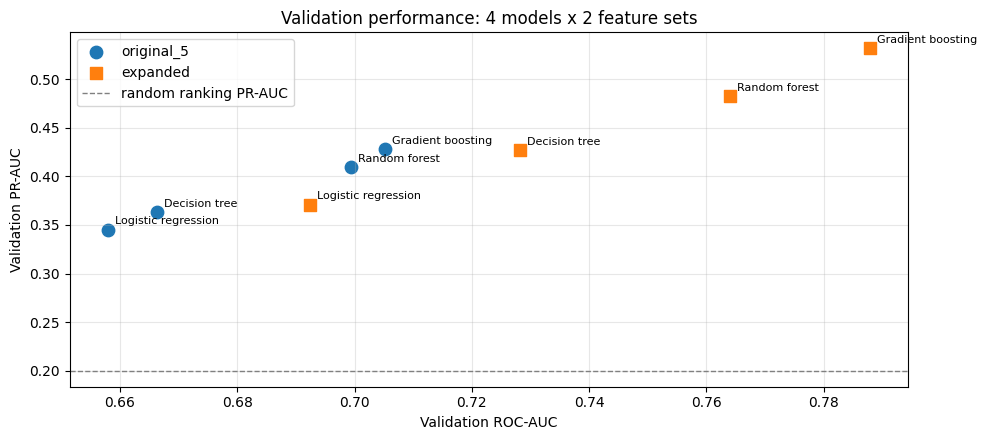

In [7]:
validation_results = pd.concat([results_original, results_expanded], ignore_index=True)
validation_results.to_csv(pf.MODELS / "validation_results.csv", index=False)

pivot = validation_results.pivot(index="Model", columns="Feature set", values=["PR-AUC", "ROC-AUC", "Lift@10%"])
display(pivot)

best = validation_results.sort_values("PR-AUC", ascending=False).iloc[0]
FINAL_SET, FINAL_MODEL = best["Feature set"], best["Model"]
final = (models_original if FINAL_SET == "original_5" else models_expanded)[FINAL_MODEL]
print(f"Selected: {FINAL_MODEL} with the {FINAL_SET} feature set "
      f"(validation PR-AUC {best['PR-AUC']:.4f}, ROC-AUC {best['ROC-AUC']:.4f})")

fig, ax = plt.subplots(figsize=(10, 4.5))
for fs, marker in [("original_5", "o"), ("expanded", "s")]:
    sub = validation_results[validation_results["Feature set"] == fs]
    ax.scatter(sub["ROC-AUC"], sub["PR-AUC"], marker=marker, s=80, label=fs)
    for _, r in sub.iterrows():
        ax.annotate(r["Model"], (r["ROC-AUC"], r["PR-AUC"]), xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.axhline(y_val.mean(), color="gray", ls="--", lw=1, label="random ranking PR-AUC")
ax.set_xlabel("Validation ROC-AUC"); ax.set_ylabel("Validation PR-AUC"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Validation performance: 4 models x 2 feature sets")
plt.tight_layout(); plt.show()

# Free the models that were not selected.
del models_original, models_expanded

## 6.7 Calibrate the selected model

Class weighting improves ranking but inflates predicted probabilities. To report a **likelihood of failure** that can be read at face value, the selected model is frozen and its scores are mapped to probabilities with isotonic regression fitted on the validation set. Calibration does not change the ranking, so ROC-AUC, PR-AUC and the review-queue metrics stay the same.

Mean predicted probability on test: uncalibrated 0.417 | calibrated 0.201 | observed failure rate 0.200
Brier score on test: uncalibrated 0.1824 | calibrated 0.1276


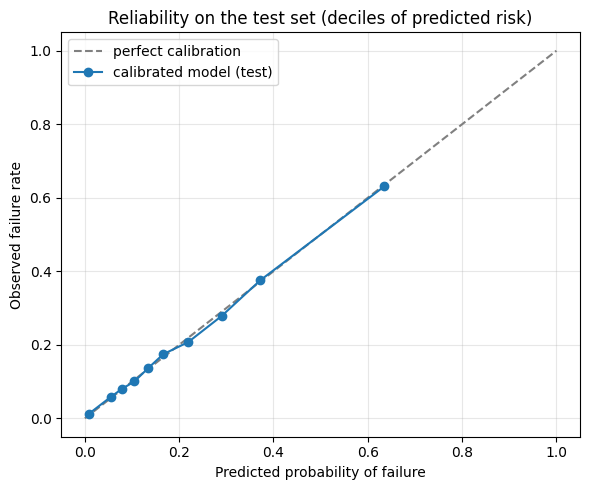

In [8]:
numeric, categorical = pf.FEATURE_SETS[FINAL_SET]
X_val = pf.model_frame(val, numeric, categorical)
X_test = pf.model_frame(test, numeric, categorical)

calibrated = CalibratedClassifierCV(FrozenEstimator(final), method="isotonic").fit(X_val, y_val)
raw_test = final.predict_proba(X_test)[:, 1]
prob_test = calibrated.predict_proba(X_test)[:, 1]

print(f"Mean predicted probability on test: uncalibrated {raw_test.mean():.3f} | calibrated {prob_test.mean():.3f} | observed failure rate {y_test.mean():.3f}")
print(f"Brier score on test: uncalibrated {brier_score_loss(y_test, raw_test):.4f} | calibrated {brier_score_loss(y_test, prob_test):.4f}")

frac_pos, mean_pred = calibration_curve(y_test, prob_test, n_bins=10, strategy="quantile")
plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
plt.plot(mean_pred, frac_pos, "o-", label="calibrated model (test)")
plt.xlabel("Predicted probability of failure"); plt.ylabel("Observed failure rate")
plt.title("Reliability on the test set (deciles of predicted risk)"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6.8 Test-set evaluation of the final model

This is the only use of the test set.

,Model,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,Gradient boosting (expanded),92310,0.2001,0.7854,0.5228,0.6130,0.3064,3.0644


,Review share,Notices reviewed,Precision@k,Recall@k,Lift@k
0,top 5%,4616,0.7409,0.1852,3.7035
1,top 10%,9231,0.6130,0.3064,3.0644
2,top 20%,18462,0.4920,0.4919,2.4595
3,top 30%,27693,0.4183,0.6273,2.0911
4,top 50%,46155,0.3257,0.8141,1.6282


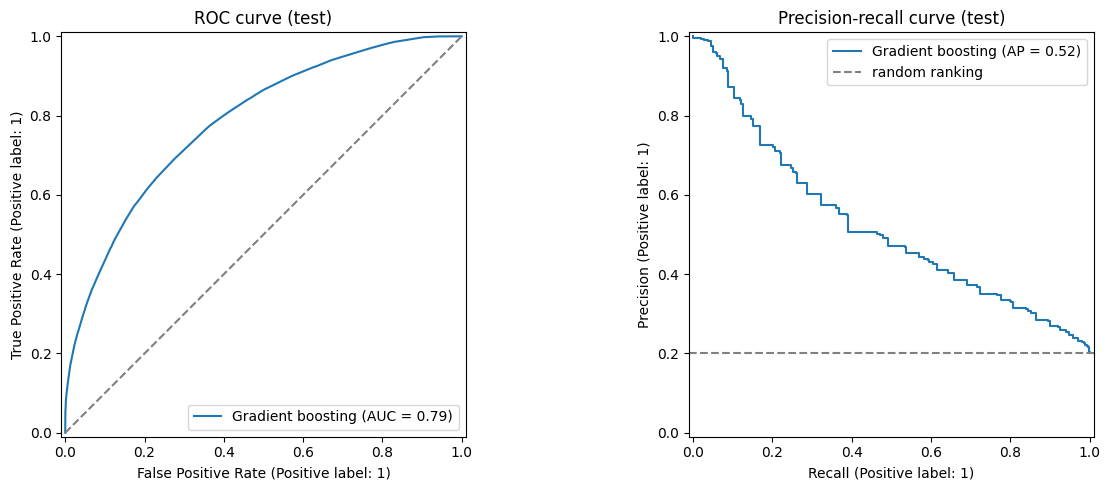

Reviewing the top 10% of test notices by predicted risk (9,231 notices) finds 61.3% failures among them, vs 20.0% at random (3.06x lift), and captures 30.6% of all failed bids in the test set.


In [9]:
test_summary = pd.DataFrame([{"Model": f"{FINAL_MODEL} ({FINAL_SET})", **pf.summary_metrics(y_test, prob_test)}])
display(test_summary)

queue = pf.queue_metrics(y_test, prob_test)
display(queue)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_test, prob_test, ax=axes[0], name=FINAL_MODEL)
axes[0].plot([0, 1], [0, 1], "--", color="gray")
PrecisionRecallDisplay.from_predictions(y_test, prob_test, ax=axes[1], name=FINAL_MODEL)
axes[1].axhline(y_test.mean(), ls="--", color="gray", label="random ranking")
axes[1].legend()
axes[0].set_title("ROC curve (test)"); axes[1].set_title("Precision-recall curve (test)")
plt.tight_layout(); plt.show()

k = queue.set_index("Review share").loc["top 10%"]
print(f"Reviewing the top 10% of test notices by predicted risk ({int(k['Notices reviewed']):,} notices) finds "
      f"{k['Precision@k'] * 100:.1f}% failures among them, vs {y_test.mean() * 100:.1f}% at random "
      f"({k['Lift@k']:.2f}x lift), and captures {k['Recall@k'] * 100:.1f}% of all failed bids in the test set.")

## 6.9 Test performance by source system and by year

The test set is random, so it mixes years and systems. Splitting the results shows whether performance holds across the merged sources. PhilGEPS 2.0 bids have a much higher failure rate than 1.5 bids. Because of this, the PR-AUC of the two systems is not directly comparable; compare each system's PR-AUC with its own failure rate, i.e. its lift.

In [10]:
test_scored = test.assign(prob=prob_test)
def by_group(col):
    rows = []
    for g, sub in test_scored.groupby(col, observed=True):
        if sub.Target_Failed.nunique() == 2 and len(sub) >= 200:
            rows.append({col: g, **pf.summary_metrics(sub.Target_Failed, sub.prob)})
    return pd.DataFrame(rows)

display(by_group("Source System"))
display(by_group("published_year"))

,Source System,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,1.5,91038,0.1975,0.7844,0.5176,0.6071,0.3074,3.0741
1,2.0,1272,0.3836,0.7641,0.6866,0.8346,0.2172,2.1756


,published_year,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,2023,30059,0.1859,0.7861,0.4977,0.5808,0.3125,3.1244
1,2024,33312,0.1819,0.7903,0.4989,0.5752,0.3161,3.1614
2,2025,18035,0.2293,0.7960,0.5862,0.7057,0.3079,3.0777
3,2026,10904,0.2461,0.7548,0.5477,0.6679,0.2713,2.7144


## 6.10 Sensitivity: counting only failed biddings as failures

The main target counts `Failed` and `Cancelled` bids as procurement failures. Here the selected configuration is refitted with `Target_Failed_Only`, where Failed = 1, Awarded = 0 and Cancelled bids are left out. Two questions:

1. How well can the narrower *failed bidding* outcome be predicted?
2. Does the main model, trained on Failed or Cancelled, still rank failed bids above awarded ones? This is checked on the same held-out bids.

**Split.** The sensitivity population (Awarded and Failed bids) is a subset of the main population, so every bid keeps its assignment from §6.1. The sensitivity model never trains on a bid from the main test set.

In [11]:
# Sensitivity population: Awarded and Failed bids only (Cancelled left out).
# Every one of these bids is also in the main population, so it keeps its split from §6.1.
sens = labelled[labelled["Target_Failed_Only"].notna()]
s_train, s_test = sens[sens.split == "train"], sens[sens.split == "test"]
y_s_test = s_test.Target_Failed_Only.astype(int)
print("Sensitivity split:", sens.split.value_counts().to_dict())

sens_model = make_models(numeric, categorical)[FINAL_MODEL]
sens_model.fit(pf.model_frame(s_train, numeric, categorical), s_train.Target_Failed_Only.astype(int))
X_s_test = pf.model_frame(s_test, numeric, categorical)
s_score = sens_model.predict_proba(X_s_test)[:, 1]
main_on_s = calibrated.predict_proba(X_s_test)[:, 1]

comparison = pd.DataFrame([
    {"Trained on": "Failed or Cancelled vs Awarded (main)", "Evaluated on": "main test set (Failed or Cancelled vs Awarded)",
     **pf.summary_metrics(y_test, prob_test)},
    {"Trained on": "Failed vs Awarded", "Evaluated on": "test set without Cancelled (Failed vs Awarded)",
     **pf.summary_metrics(y_s_test, s_score)},
    {"Trained on": "Failed or Cancelled vs Awarded (main)", "Evaluated on": "test set without Cancelled (Failed vs Awarded)",
     **pf.summary_metrics(y_s_test, main_on_s)},
])
display(comparison)
print(f"Sensitivity population: {len(sens):,} bids, positive rate {sens.Target_Failed_Only.mean() * 100:.1f}%")

Sensitivity split: {'train': 390997, 'validation': 83819, 'test': 83716}


,Trained on,Evaluated on,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,Failed or Cancelled vs Awarded (main),main test set (Failed or Cancelled vs Awarded),92310,0.2001,0.7854,0.5228,0.6130,0.3064,3.0644
1,Failed vs Awarded,test set without Cancelled (Failed vs Awarded),83716,0.1179,0.8417,0.4924,0.4976,0.4220,4.2194
2,Failed or Cancelled vs Awarded (main),test set without Cancelled (Failed vs Awarded),83716,0.1179,0.8189,0.4512,0.4710,0.3994,3.9935


Sensitivity population: 558,532 bids, positive rate 11.9%


## 6.11 Save the final model

The fitted pipeline, the calibrated model and the configuration are saved under `data/processed/models/`, which Git ignores, for use in notebook 03.

In [12]:
joblib.dump(final, pf.MODELS / "final_pipeline.joblib", compress=3)
joblib.dump(calibrated, pf.MODELS / "final_calibrated.joblib", compress=3)
config = {"feature_set": FINAL_SET, "model": FINAL_MODEL,
          "numeric": numeric, "categorical": categorical,
          "validation_pr_auc": float(best["PR-AUC"]),
          "test": {k: float(v) for k, v in pf.summary_metrics(y_test, prob_test).items()}}
(pf.MODELS / "final_config.json").write_text(json.dumps(config, indent=2))
queue.to_csv(pf.MODELS / "test_queue_metrics.csv", index=False)
comparison.to_csv(pf.MODELS / "sensitivity_failed_only.csv", index=False)
print(json.dumps(config, indent=2))

{
  "feature_set": "expanded",
  "model": "Gradient boosting",
  "numeric": [
    "log_approved_budget",
    "bidding_window_days",
    "log_n_line_items",
    "log_contract_duration_days",
    "multi_funding_source"
  ],
  "categorical": [
    "Funding Source",
    "Business Category",
    "Region",
    "published_month",
    "Classification",
    "PE Organization Type (Grouped)",
    "Government Branch",
    "Funding Instrument",
    "Trade Agreement",
    "Lot Type",
    "published_dayofweek",
    "Source System"
  ],
  "validation_pr_auc": 0.5317294634485642,
  "test": {
    "n": 92310.0,
    "failure rate": 0.20005416531253387,
    "ROC-AUC": 0.7853523799039269,
    "PR-AUC": 0.5228101892759176,
    "Precision@10%": 0.6130430072581519,
    "Recall@10%": 0.3064385119402177,
    "Lift@10%": 3.0643851194021767
  }
}
